![Python Banner](../../Image/05_06_Baysian_CausalML.png)


# 6.1 Bayesian Causal Inference



This notebook combines five Bayesian designs for estimating causal effects: A/B testing, difference-in-differences, interrupted time series, instrumental variables, and propensity methods. Each design is self-contained. It states the identifying assumption, simulates data with a known effect, fits a PyMC model, and reads the posterior as a decision.


## Overview

The five designs answer different questions about how treatment was assigned.

| Section | Design | Use it when | Target |
| --- | --- | --- | --- |
| [6.1](#61-bayesian-ab-testing) | Bayesian A/B testing | Treatment is randomized | Probability that B beats A, and the posterior of the lift |
| [6.2](#62-bayesian-difference-in-differences) | Bayesian difference-in-differences | Treated and control units are observed before and after | Posterior of the treatment effect under parallel trends |
| [6.3](#63-bayesian-interrupted-time-series) | Bayesian interrupted time series | One series is interrupted at a known time and no control group exists | Posterior of the level change and the trend change |
| [6.4](#64-bayesian-instrumental-variables) | Bayesian instrumental variables | Treatment is confounded by unobservables and a valid instrument exists | Posterior of the local average treatment effect |
| [6.5](#65-bayesian-propensity-methods) | Bayesian propensity methods | Treatment is self-selected on observed covariates | Posterior of the effect, with uncertainty from the propensity model |

Across all five sections, the Bayesian step is the same: place priors on the causal parameter, sample the posterior, and report a probability statement and a credible interval. Priors can borrow strength from historical results. They do not repair a broken design. Parallel trends, the exclusion restriction, and overlap still have to hold.

### Contents

1. [Bayesian A/B Testing](#61-bayesian-ab-testing)
2. [Bayesian Difference-in-Differences](#62-bayesian-difference-in-differences)
3. [Bayesian Interrupted Time Series](#63-bayesian-interrupted-time-series)
4. [Bayesian Instrumental Variables](#64-bayesian-instrumental-variables)
5. [Bayesian Propensity Methods](#65-bayesian-propensity-methods)


## Setup

Install the packages used across the five designs, then import them once. Later sections reuse these imports. `causalpy` is used for the CausalPy difference-in-differences example. `statsmodels` and `scikit-learn` are imported in the instrumental-variables and propensity sections where those comparisons are fit.


In [1]:
%pip install -q numpy pandas matplotlib seaborn pymc arviz causalpy statsmodels scikit-learn


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu12 26.2.1 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
ydata-profiling 4.18.4 requires numba<0.63,>=0.60, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuxfilter-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuxfilter-cu12 26.2.0 requires shapely<2.1.0, but you have shapely 2.1.2 which is incompatible.
cugraph-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pymc as pm
import arviz as az
import causalpy as cp

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


/home/zia207/.pyenv/versions/3.11.14/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


# 6.1 Bayesian A/B Testing

Bayesian A/B testing provides a natural framework for analyzing randomized experiments, with explicit uncertainty quantification and the ability to incorporate prior knowledge. This chapter covers Bayesian approaches to A/B testing using PyMC.

## Overview

### Why Bayesian A/B Testing?

Traditional (frequentist) A/B testing uses hypothesis testing and p-values. Bayesian A/B testing offers several advantages:

1. **Intuitive probability statements**: "There's a 95% probability that variant B outperforms A" vs. "We reject the null hypothesis at p < 0.05"

2. **Sequential analysis**: You can stop experiments early when results are clear, without inflating Type I error

3. **Incorporating prior knowledge**: Historical test results or domain expertise can be encoded as priors

4. **Small sample performance**: With informative priors, reliable conclusions can be drawn from small samples

5. **Risk-aware decision-making**: Posterior distributions enable loss functions and expected value calculations

### The Bayesian A/B Testing Framework

In Bayesian A/B testing, we model the outcome for each variant as a random variable with a prior distribution. After observing data, we compute the posterior distribution for each variant's metric.

For common metrics:

- **Conversion rate (binary outcome)**: Beta-Binomial model
- **Revenue (continuous outcome)**: Normal-Gamma model
- **Count data (e.g., transactions)**: Poisson-Gamma model

The key output is the posterior distribution of the **lift** (difference between variants), from which we can compute:

- **Probability that B > A**: $P(\mu_B > \mu_A \mid \text{data})$
- **Expected lift**: $E[\mu_B - \mu_A \mid \text{data}]$
- **Credible interval for lift**: 95% HDI of $\mu_B - \mu_A$

### Business Setting

Bayesian A/B testing is ideal when:

- **Sample sizes are limited**: Pilot tests, early-stage experiments
- **Prior knowledge exists**: Historical conversion rates, expert judgment
- **Sequential monitoring**: You want to check results continuously
- **Risk quantification**: You need to quantify the probability of negative outcomes
- **Decision flexibility**: Stopping rules based on posterior probabilities

Common business applications:

- Website conversion rate testing
- Marketing campaign effectiveness
- Pricing experiments
- Feature rollout impact
- Email marketing optimization

## Example 1: Conversion Rate Testing (Beta-Binomial)

For binary outcomes (convert/don't convert), we use the Beta-Binomial model:

- **Prior**: Beta distribution for conversion rate
- **Likelihood**: Binomial distribution for observed conversions
- **Posterior**: Beta distribution (conjugate prior)

Let's simulate an A/B test for website conversion:

In [3]:
# Simulate A/B test data
np.random.seed(42)

# Variant A: control
n_A = 1000
true_rate_A = 0.10
conversions_A = np.random.binomial(n_A, true_rate_A)

# Variant B: treatment (5% relative lift)
n_B = 1000
true_rate_B = 0.105
conversions_B = np.random.binomial(n_B, true_rate_B)

print(f"Variant A: {conversions_A}/{n_A} conversions ({conversions_A/n_A:.3f})")
print(f"Variant B: {conversions_B}/{n_B} conversions ({conversions_B/n_B:.3f})")
print(f"Observed lift: {(conversions_B/n_B - conversions_A/n_A):.3f}")

Variant A: 96/1000 conversions (0.096)
Variant B: 107/1000 conversions (0.107)
Observed lift: 0.011


Now let's fit a Bayesian model:

In [4]:
with pm.Model() as conversion_model:
    # Priors for conversion rates (weakly informative)
    # Beta(1, 1) is uniform on [0, 1]
    rate_A = pm.Beta("rate_A", alpha=1, beta=1)
    rate_B = pm.Beta("rate_B", alpha=1, beta=1)
    
    # Lift (relative improvement)
    lift = pm.Deterministic("lift", (rate_B - rate_A) / rate_A)
    
    # Likelihood
    pm.Binomial("conversions_A", n=n_A, p=rate_A, observed=conversions_A)
    pm.Binomial("conversions_B", n=n_B, p=rate_B, observed=conversions_B)
    
    # Sample from posterior
    trace_conversion = pm.sample(2000, tune=1000, chains=4, target_accept=0.95)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [rate_A, rate_B]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 2 seconds.


Let's examine the results:

In [5]:
# Posterior summary
az.summary(trace_conversion, var_names=["rate_A", "rate_B", "lift"], hdi_prob=0.95)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
rate_A,0.097,0.009,0.079,0.116,0.000,0.000,"5,441.000","4,160.000",1.000
rate_B,0.108,0.010,0.089,0.127,0.000,0.000,"5,537.000","4,519.000",1.000
lift,0.126,0.148,-0.152,0.418,0.002,0.002,"5,162.000","4,795.000",1.000


In [6]:
# Probability that B is better than A
prob_B_better = (trace_conversion.posterior["rate_B"] > trace_conversion.posterior["rate_A"]).mean()
print(f"P(rate_B > rate_A) = {prob_B_better:.3f}")

P(rate_B > rate_A) = 0.801


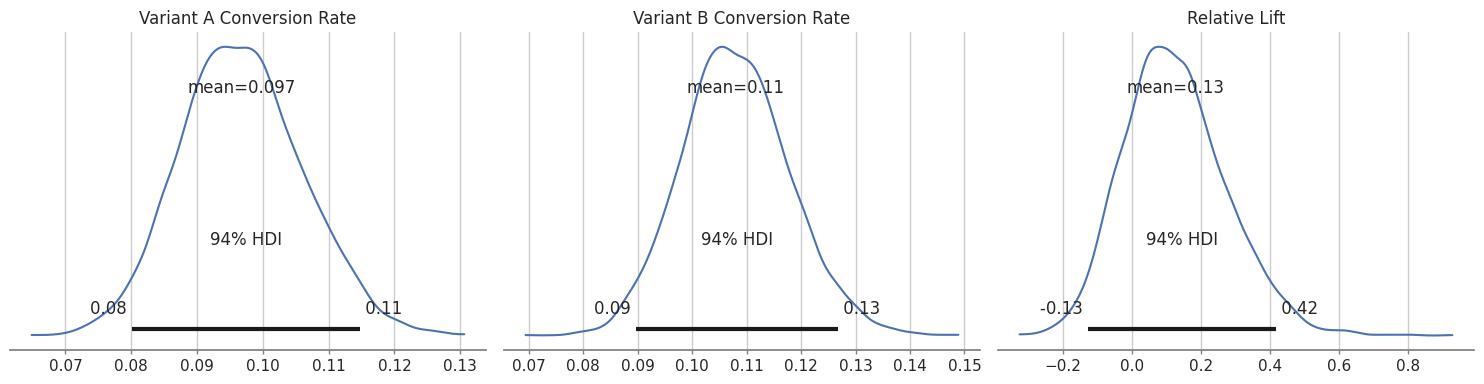

In [7]:
# Plot posterior distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

az.plot_posterior(trace_conversion, var_names=["rate_A"], ax=axes[0])
axes[0].set_title("Variant A Conversion Rate")

az.plot_posterior(trace_conversion, var_names=["rate_B"], ax=axes[1])
axes[1].set_title("Variant B Conversion Rate")

az.plot_posterior(trace_conversion, var_names=["lift"], ax=axes[2])
axes[2].set_title("Relative Lift")

plt.tight_layout()
plt.show()

The posterior gives us:

- **Conversion rate estimates**: Posterior means for each variant
- **Lift distribution**: Full uncertainty about the relative improvement
- **Probability of success**: P(B > A) — directly actionable for decision-making

For example, if P(B > A) = 0.95, we can say "There's a 95% probability that variant B outperforms A."

## Example 2: Incorporating Prior Knowledge

One of Bayesian methods' strengths is incorporating prior knowledge. Let's use informative priors based on historical data:

In [8]:
# Suppose historical data suggests conversion rates are around 10% with some variation
# We encode this as Beta(10, 90) which has mean 0.10 and moderate uncertainty

with pm.Model() as conversion_model_informative:
    # Informative priors based on historical data
    rate_A = pm.Beta("rate_A", alpha=10, beta=90)
    rate_B = pm.Beta("rate_B", alpha=10, beta=90)
    
    lift = pm.Deterministic("lift", (rate_B - rate_A) / rate_A)
    
    pm.Binomial("conversions_A", n=n_A, p=rate_A, observed=conversions_A)
    pm.Binomial("conversions_B", n=n_B, p=rate_B, observed=conversions_B)
    
    trace_informative = pm.sample(2000, tune=1000, chains=4, target_accept=0.95)

# Compare results
print("Weakly informative priors:")
print(az.summary(trace_conversion, var_names=["lift"], hdi_prob=0.95))

print("\nInformative priors:")
print(az.summary(trace_informative, var_names=["lift"], hdi_prob=0.95))

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [rate_A, rate_B]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 2 seconds.


Weakly informative priors:
      mean    sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
lift 0.126 0.148    -0.152      0.418      0.002    0.002 5,162.000 4,795.000   

      r_hat  
lift  1.000  

Informative priors:
      mean    sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
lift 0.112 0.142    -0.158      0.390      0.002    0.002 5,557.000 5,342.000   

      r_hat  
lift  1.000  


With informative priors, the posterior is more precise (narrower credible intervals). This is particularly useful with small samples.

## Example 3: Revenue Testing (Normal-Gamma)

For continuous outcomes like revenue, we use a Normal likelihood with a Gamma prior on the standard deviation:

In [9]:
# Simulate revenue data
np.random.seed(42)

n_A_rev = 500
n_B_rev = 500

# Variant A: mean $50, std $20
revenue_A = np.random.normal(50, 20, n_A_rev)

# Variant B: mean $55, std $20 (10% lift)
revenue_B = np.random.normal(55, 20, n_B_rev)

print(f"Variant A mean revenue: ${revenue_A.mean():.2f}")
print(f"Variant B mean revenue: ${revenue_B.mean():.2f}")
print(f"Observed lift: ${(revenue_B.mean() - revenue_A.mean()):.2f}")

Variant A mean revenue: $50.14
Variant B mean revenue: $55.64
Observed lift: $5.50


In [10]:
with pm.Model() as revenue_model:
    # Priors for means
    mu_A = pm.Normal("mu_A", mu=50, sigma=20)
    mu_B = pm.Normal("mu_B", mu=50, sigma=20)
    
    # Prior for standard deviation (half-normal)
    sigma = pm.HalfNormal("sigma", sigma=20)
    
    # Absolute lift
    lift_abs = pm.Deterministic("lift_abs", mu_B - mu_A)
    
    # Relative lift
    lift_rel = pm.Deterministic("lift_rel", (mu_B - mu_A) / mu_A)
    
    # Likelihood
    pm.Normal("revenue_A", mu=mu_A, sigma=sigma, observed=revenue_A)
    pm.Normal("revenue_B", mu=mu_B, sigma=sigma, observed=revenue_B)
    
    trace_revenue = pm.sample(2000, tune=1000, chains=4, target_accept=0.95)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu_A, mu_B, sigma]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 4 seconds.


In [11]:
# Posterior summary
az.summary(trace_revenue, var_names=["mu_A", "mu_B", "lift_abs", "lift_rel"], hdi_prob=0.95)

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_A,50.135,0.854,48.486,51.780,0.009,0.009,"8,466.000","5,588.000",1.000
mu_B,55.636,0.892,53.860,57.333,0.010,0.010,"7,895.000","5,270.000",1.000
lift_abs,5.501,1.235,3.073,7.815,0.014,0.013,"7,984.000","5,806.000",1.000
lift_rel,0.110,0.026,0.061,0.161,0.000,0.000,"8,020.000","6,064.000",1.000


In [12]:
# Probability that B has higher revenue
prob_B_better_rev = (trace_revenue.posterior["mu_B"] > trace_revenue.posterior["mu_A"]).mean()
print(f"P(revenue_B > revenue_A) = {prob_B_better_rev:.3f}")

P(revenue_B > revenue_A) = 1.000


## Decision Rules

Bayesian A/B testing enables flexible decision rules based on posterior probabilities:

In [13]:
# Decision rule: adopt B if P(B > A) > 0.95 and expected lift > 2%
prob_threshold = 0.95
lift_threshold = 0.02

expected_lift = trace_conversion.posterior["lift"].mean()
prob_better = (trace_conversion.posterior["rate_B"] > trace_conversion.posterior["rate_A"]).mean()

print(f"Expected lift: {expected_lift:.3f}")
print(f"P(B > A): {prob_better:.3f}")

if prob_better > prob_threshold and expected_lift > lift_threshold:
    print("Decision: ADOPT variant B")
else:
    print("Decision: CONTINUE testing or adopt A")

Expected lift: 0.126
P(B > A): 0.801
Decision: CONTINUE testing or adopt A


## Sequential Monitoring

One advantage of Bayesian methods is the ability to monitor results sequentially without inflating Type I error. Here's a simple example:

In [15]:
# Simulate sequential data (cumulative over time)
np.random.seed(42)
n_periods = 10
n_per_period = 100

sequential_results = []

for period in range(1, n_periods + 1):
    # Cumulative data up to this period
    n_cum = period * n_per_period
    conv_A_cum = np.random.binomial(n_cum, 0.10)
    conv_B_cum = np.random.binomial(n_cum, 0.105)
    
    # Fit model (simplified for speed)
    with pm.Model() as seq_model:
        rate_A = pm.Beta("rate_A", alpha=1, beta=1)
        rate_B = pm.Beta("rate_B", alpha=1, beta=1)
        lift = pm.Deterministic("lift", (rate_B - rate_A) / rate_A)
        pm.Binomial("conv_A", n=n_cum, p=rate_A, observed=conv_A_cum)
        pm.Binomial("conv_B", n=n_cum, p=rate_B, observed=conv_B_cum)
        trace_seq = pm.sample(1000, tune=500, chains=2, target_accept=0.95)
    
    prob_better = (trace_seq.posterior["rate_B"] > trace_seq.posterior["rate_A"]).mean()
    expected_lift = trace_seq.posterior["lift"].mean()
    
    sequential_results.append({
        "period": period,
        "n": n_cum,
        "prob_better": prob_better,
        "expected_lift": expected_lift
    })

seq_df = pd.DataFrame(sequential_results)
print(seq_df)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [rate_A, rate_B]


Output()

Sampling 2 chains for 500 tune and 1_000 draw iterations (1_000 + 2_000 draws total) took 1 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [rate_A, rate_B]


Output()

Sampling 2 chains for 500 tune and 1_000 draw iterations (1_000 + 2_000 draws total) took 1 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [rate_A, rate_B]


...

Output()

Sampling 2 chains for 500 tune and 1_000 draw iterations (1_000 + 2_000 draws total) took 1 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [rate_A, rate_B]


Output()

Sampling 2 chains for 500 tune and 1_000 draw iterations (1_000 + 2_000 draws total) took 1 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


   period     n                                    prob_better  \
0       1   100   <xarray.DataArray ()> Size: 8B\narray(0.929)   
1       2   200  <xarray.DataArray ()> Size: 8B\narray(0.4405)   
2       3   300   <xarray.DataArray ()> Size: 8B\narray(0.874)   
3       4   400   <xarray.DataArray ()> Size: 8B\narray(0.975)   
4       5   500  <xarray.DataArray ()> Size: 8B\narray(0.2885)   
5       6   600  <xarray.DataArray ()> Size: 8B\narray(0.2275)   
6       7   700  <xarray.DataArray ()> Size: 8B\narray(0.6195)   
7       8   800   <xarray.DataArray ()> Size: 8B\narray(0.738)   
8       9   900   <xarray.DataArray ()> Size: 8B\narray(0.191)   
9      10  1000  <xarray.DataArray ()> Size: 8B\narray(0.9085)   

                                       expected_lift  
0  <xarray.DataArray 'lift' ()> Size: 8B\narray(0...  
1  <xarray.DataArray 'lift' ()> Size: 8B\narray(-...  
2  <xarray.DataArray 'lift' ()> Size: 8B\narray(0...  
3  <xarray.DataArray 'lift' ()> Size: 8B\narray(0... 

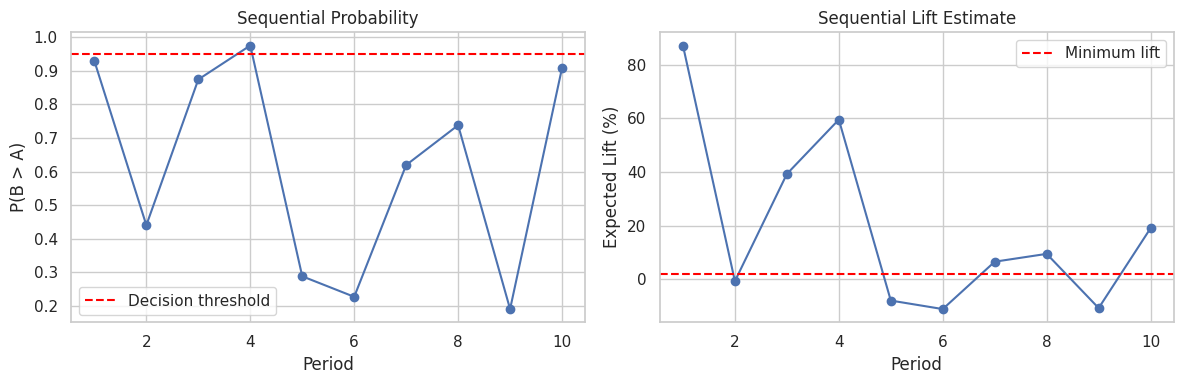

In [16]:
# Plot sequential results
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(seq_df["period"], seq_df["prob_better"], marker="o")
axes[0].axhline(0.95, color="red", ls="--", label="Decision threshold")
axes[0].set_xlabel("Period")
axes[0].set_ylabel("P(B > A)")
axes[0].set_title("Sequential Probability")
axes[0].legend()

axes[1].plot(seq_df["period"], seq_df["expected_lift"] * 100, marker="o")
axes[1].axhline(2, color="red", ls="--", label="Minimum lift")
axes[1].set_xlabel("Period")
axes[1].set_ylabel("Expected Lift (%)")
axes[1].set_title("Sequential Lift Estimate")
axes[1].legend()

plt.tight_layout()
plt.show()

## Common Pitfalls

### 1. Peeking with Frequentist Methods

With frequentist methods, checking results repeatedly inflates Type I error. Bayesian methods avoid this, but you should still pre-specify decision rules.

**Solution**: Pre-specify stopping rules (e.g., "stop when P(B > A) > 0.95 and n > 1000").

### 2. Overly Informative Priors

Priors that are too strong can dominate the data, especially with large samples.

**Solution**: Use weakly informative priors by default, only use informative priors when you have strong justification.

### 3. Ignoring Model Diagnostics

Poor MCMC convergence can produce misleading results.

**Solution**: Always check R-hat statistics, trace plots, and effective sample size.

### 4. Misinterpreting Credible Intervals

Credible intervals are probability statements about parameters, not about future data.

**Solution**: Be precise in communication: "There's a 95% probability the true conversion rate is in this interval."

## When to Use Bayesian A/B Testing

Bayesian A/B testing is the right choice when:

- **Sample sizes are limited**: Small experiments, pilot tests
- **Prior knowledge exists**: Historical data, expert judgment
- **Sequential monitoring**: You want to check results continuously
- **Risk quantification**: You need probability statements for decision-making
- **Complex metrics**: Multi-variate testing, hierarchical experiments

Consider frequentist methods when:

- Large samples with no prior knowledge
- Regulatory requirements specify frequentist methods
- Simplicity and speed are paramount
- Stakeholders are unfamiliar with Bayesian methods

## Summary

Bayesian A/B testing provides a natural framework for analyzing randomized experiments with explicit uncertainty quantification and the ability to incorporate prior knowledge.

**Key takeaways:**

- Bayesian methods give intuitive probability statements (P(B > A) = 0.95)
- Use Beta-Binomial for conversion rates, Normal-Gamma for continuous outcomes
- Informative priors can improve small-sample performance
- Sequential monitoring is possible without inflating Type I error
- Always check MCMC diagnostics (R-hat, trace plots)
- Pre-specify decision rules to avoid "peeking" bias
- Communicate results as probability statements, not just point estimates

## Scientific Terminology

Plain-language definitions for the terms in this tutorial are in the [scientific terminology glossary](../00-scientific-terminology-glossary.qmd).


# 6.2 Bayesian Difference-in-Differences

Bayesian Difference-in-Differences (DiD) provides a probabilistic framework for estimating treatment effects in panel data, with full uncertainty quantification and the ability to incorporate prior knowledge about effect sizes and trends.

## Overview

### Why Bayesian DiD?

Bayesian DiD extends the frequentist DiD framework with several advantages:

1. **Full uncertainty propagation**: Uncertainty from trend estimation, variance components, and treatment effects all flow through to the final estimate

2. **Prior knowledge incorporation**: Historical results or domain expertise about effect sizes can be encoded as priors

3. **Flexible time-series modeling**: Bayesian state-space models can handle complex temporal dynamics

4. **Hierarchical structure**: Multiple treated units can share information through hierarchical priors

5. **Small cluster performance**: With few treated groups, Bayesian methods can stabilize estimates using informative priors

### The Bayesian DiD Model

The basic Bayesian DiD model extends the frequentist two-way fixed effects specification:

$$
Y_{it} = \alpha_i + \lambda_t + \tau \, D_{it} + \varepsilon_{it}
$$

In a Bayesian framework, we place priors on:

- $\alpha_i$: Unit fixed effects (can be hierarchical if many units)
- $\lambda_t$: Time fixed effects (can be modeled as random walks)
- $\tau$: Treatment effect (the parameter of interest)
- $\sigma^2$: Error variance

This gives us a full posterior distribution for $\tau$, not just a point estimate and standard error.

### Business Setting

Bayesian DiD is ideal when:

- **Few treated clusters**: Limited number of treated markets/regions
- **Prior knowledge exists**: Historical rollout results, effect size expectations
- **Complex temporal dynamics**: Seasonality, trends, or autocorrelation
- **Hierarchical structure**: Multiple treated units that might share effects
- **Full uncertainty needed**: Decision-makers need probability statements

Common business applications:

- Geographic rollout evaluation
- Policy impact assessment
- Marketing campaign effectiveness across regions
- Store format testing

## Example 1: Basic Bayesian DiD with PyMC

Let's implement a basic Bayesian DiD model using PyMC:

In [ ]:
# Simulate panel data
np.random.seed(42)

n_units = 20
n_time = 50
treat_time = 30
true_effect = 5.0

# Unit fixed effects
alpha = np.random.normal(100, 10, n_units)

# Time fixed effects (trend + seasonality)
time = np.arange(n_time)
lambda_t = 0.1 * time + 5 * np.sin(2 * np.pi * time / 12)

# Treatment assignment (first 10 units treated)
treated = np.arange(n_units) < 10

# Generate data
data = []
for i in range(n_units):
    for t in range(n_time):
        D = 1 if (treated[i] and t >= treat_time) else 0
        y = alpha[i] + lambda_t[t] + true_effect * D + np.random.normal(0, 3)
        data.append({"unit": i, "time": t, "treated": int(treated[i]), "D": D, "y": y})

df = pd.DataFrame(data)
print(df.head())

Now let's fit a Bayesian DiD model:

In [ ]:
# Prepare data for PyMC
unit_idx = df["unit"].values
time_idx = df["time"].values
D = df["D"].values
y = df["y"].values

n_units_obs = len(df["unit"].unique())
n_time_obs = len(df["time"].unique())

with pm.Model() as did_model:
    # Priors for unit fixed effects (hierarchical)
    mu_alpha = pm.Normal("mu_alpha", mu=100, sigma=20)
    sigma_alpha = pm.HalfNormal("sigma_alpha", sigma=10)
    alpha_i = pm.Normal("alpha_i", mu=mu_alpha, sigma=sigma_alpha, shape=n_units_obs)
    
    # Priors for time fixed effects (hierarchical)
    mu_lambda = pm.Normal("mu_lambda", mu=0, sigma=10)
    sigma_lambda = pm.HalfNormal("sigma_lambda", sigma=5)
    lambda_t = pm.Normal("lambda_t", mu=mu_lambda, sigma=sigma_lambda, shape=n_time_obs)
    
    # Prior for treatment effect
    tau = pm.Normal("tau", mu=0, sigma=10)
    
    # Prior for error variance
    sigma = pm.HalfNormal("sigma", sigma=5)
    
    # Linear predictor
    mu = alpha_i[unit_idx] + lambda_t[time_idx] + tau * D
    
    # Likelihood
    pm.Normal("y", mu=mu, sigma=sigma, observed=y)
    
    # Sample from posterior
    trace_did = pm.sample(2000, tune=1000, chains=4, target_accept=0.95)

Let's examine the posterior of the treatment effect:

In [ ]:
# Posterior summary
az.summary(trace_did, var_names=["tau"], hdi_prob=0.95)

In [ ]:
# Plot posterior
az.plot_posterior(trace_did, var_names=["tau"], hdi_prob=0.95, ref_val=true_effect)
plt.title(f"Posterior of Treatment Effect (True = {true_effect})")
plt.tight_layout()
plt.show()

The posterior should be centered near the true effect of 5.0, with uncertainty reflecting the data.

## Example 2: Bayesian DiD with CausalPy

CausalPy provides a convenient interface for Bayesian causal inference. Let's use it for DiD analysis:

In [ ]:
# Prepare data for CausalPy
df_causalpy = df.copy()
df_causalpy["treatment_time"] = np.where(df_causalpy["time"] >= treat_time, 1, 0)
df_causalpy["group"] = np.where(df_causalpy["treated"] == 1, "treated", "control")

# Use CausalPy for Bayesian DiD
# Note: CausalPy uses PyMC under the hood
result = cp.pymc_experiments.PrePostFit(
    df=df_causalpy,
    treatment="treated",
    outcome="y",
    time="time",
    formula="y ~ 1 + time + treated",
    model=cp.pymc_models.LinearRegression,
    time_variable_name="time",
)

print(result.summary())

## Example 3: Incorporating Prior Knowledge

Let's use an informative prior for the treatment effect based on historical knowledge:

In [ ]:
# Suppose historical data suggests effects are around 4 with uncertainty ±2
with pm.Model() as did_model_informative:
    # Informative prior for treatment effect
    tau = pm.Normal("tau", mu=4, sigma=2)
    
    # Other priors
    mu_alpha = pm.Normal("mu_alpha", mu=100, sigma=20)
    sigma_alpha = pm.HalfNormal("sigma_alpha", sigma=10)
    alpha_i = pm.Normal("alpha_i", mu=mu_alpha, sigma=sigma_alpha, shape=n_units_obs)
    
    mu_lambda = pm.Normal("mu_lambda", mu=0, sigma=10)
    sigma_lambda = pm.HalfNormal("sigma_lambda", sigma=5)
    lambda_t = pm.Normal("lambda_t", mu=mu_lambda, sigma=sigma_lambda, shape=n_time_obs)
    
    sigma = pm.HalfNormal("sigma", sigma=5)
    
    mu = alpha_i[unit_idx] + lambda_t[time_idx] + tau * D
    pm.Normal("y", mu=mu, sigma=sigma, observed=y)
    
    trace_did_inf = pm.sample(2000, tune=1000, chains=4, target_accept=0.95)

# Compare results
print("Weakly informative prior:")
print(az.summary(trace_did, var_names=["tau"], hdi_prob=0.95))

print("\nInformative prior:")
print(az.summary(trace_did_inf, var_names=["tau"], hdi_prob=0.95))

With an informative prior, the posterior is "shrunk" toward the prior. This is useful with small samples or strong prior knowledge.

## Example 4: Dynamic Effects (Event Study)

We can extend the model to estimate dynamic effects over time:

In [ ]:
# Create leads and lags relative to treatment
df["rel_time"] = np.where(df["treated"] == 1, df["time"] - treat_time, np.nan)

# Bin leads/lags
df["rel_time_binned"] = df["rel_time"].clip(-10, 10)

# Create treatment x time interaction dummies
time_dummies = pd.get_dummies(df["rel_time_binned"], prefix="k", dtype=float)
time_dummies = time_dummies.drop(columns=["k_nan"])
df = pd.concat([df, time_dummies], axis=1).fillna(0)

# Select interaction columns
k_cols = [c for c in df.columns if c.startswith("k_")]

# Event study model
with pm.Model() as event_study_model:
    # Dynamic treatment effects
    tau_k = pm.Normal("tau_k", mu=0, sigma=5, shape=len(k_cols))
    
    # Fixed effects
    mu_alpha = pm.Normal("mu_alpha", mu=100, sigma=20)
    sigma_alpha = pm.HalfNormal("sigma_alpha", sigma=10)
    alpha_i = pm.Normal("alpha_i", mu=mu_alpha, sigma=sigma_alpha, shape=n_units_obs)
    
    mu_lambda = pm.Normal("mu_lambda", mu=0, sigma=10)
    sigma_lambda = pm.HalfNormal("sigma_lambda", sigma=5)
    lambda_t = pm.Normal("lambda_t", mu=mu_lambda, sigma=sigma_lambda, shape=n_time_obs)
    
    sigma = pm.HalfNormal("sigma", sigma=5)
    
    # Linear predictor with dynamic effects
    dynamic_effect = pm.math.dot(df[k_cols].values, tau_k)
    mu = alpha_i[unit_idx] + lambda_t[time_idx] + dynamic_effect
    
    pm.Normal("y", mu=mu, sigma=sigma, observed=y)
    
    trace_event = pm.sample(2000, tune=1000, chains=4, target_accept=0.95)

In [ ]:
# Extract and plot dynamic effects
tau_post = trace_event.posterior["tau_k"].mean(dim=["chain", "draw"]).values
time_points = np.arange(-10, 11)

plt.figure(figsize=(10, 4))
plt.plot(time_points, tau_post, marker="o")
plt.axvline(0, color="red", ls="--", label="Treatment")
plt.axhline(0, color="gray", ls="-")
plt.xlabel("Time relative to treatment")
plt.ylabel("Treatment effect")
plt.title("Dynamic Treatment Effects (Event Study)")
plt.legend()
plt.tight_layout()
plt.show()

The event study plot shows:

- **Pre-treatment**: Effects should be near zero (no pre-trend)
- **Post-treatment**: The trajectory of the effect over time

This is a powerful diagnostic for parallel trends and effect dynamics.

## Model Diagnostics

Always check MCMC diagnostics:

In [ ]:
# Check convergence
print("R-hat statistics:")
print(az.rhat(trace_did))

# Trace plots
az.plot_trace(trace_did, var_names=["tau"])
plt.tight_layout()
plt.show()

## Common Pitfalls

### 1. Poor Parallel Trends

Even in Bayesian DiD, the parallel trends assumption is critical. Priors cannot fix violated assumptions.

**Solution**: Always check pre-trends visually and with event-study models.

### 2. Overconfident Priors

Priors that are too narrow can overwhelm the data, especially with large samples.

**Solution**: Use weakly informative priors by default; only use informative priors with strong justification.

### 3. Computational Issues

Hierarchical models with many units can be slow to fit.

**Solution**: Use non-centered parameterizations, increase `target_accept`, or use variational inference for exploration.

## When to Use Bayesian DiD

Bayesian DiD is the right choice when:

- **Few treated clusters**: Limited number of treated groups
- **Prior knowledge exists**: Historical effect estimates, domain expertise
- **Complex dynamics**: Seasonality, trends, or autocorrelation
- **Hierarchical structure**: Multiple treated units sharing information
- **Full uncertainty needed**: Probability statements for decision-making

Consider frequentist DiD when:

- Many treated clusters with large samples
- No prior knowledge
- Computation speed is critical
- Stakeholders require frequentist methods

## Summary

Bayesian DiD extends the frequentist framework with full uncertainty quantification and the ability to incorporate prior knowledge.

**Key takeaways:**

- Bayesian DiD gives full posterior distributions for treatment effects
- Hierarchical priors can stabilize estimates with few treated clusters
- Informative priors incorporate historical knowledge
- Event-study models estimate dynamic effects over time
- Always check MCMC diagnostics (R-hat, trace plots)
- Parallel trends assumption is still critical — priors don't fix violated assumptions
- CausalPy provides a convenient interface for Bayesian causal inference

## Scientific Terminology

Plain-language definitions for the terms in this tutorial are in the [scientific terminology glossary](../00-scientific-terminology-glossary.qmd).


# 6.3 Bayesian Interrupted Time Series

Bayesian Interrupted Time Series (ITS) provides a flexible framework for evaluating interventions when there's a single treated unit with a time series of outcomes before and after the intervention. Bayesian methods handle complex temporal dynamics and propagate uncertainty naturally.

## Overview

### Why Bayesian ITS?

Bayesian ITS extends the frequentist ITS framework with several advantages:

1. **Flexible time-series modeling**: Bayesian state-space models can handle complex temporal patterns, seasonality, and autocorrelation

2. **Uncertainty propagation**: Uncertainty from trend estimation, variance components, and intervention effects all flow through to the final estimate

3. **Prior knowledge incorporation**: Historical patterns or domain expertise can be encoded as priors

4. **Probabilistic forecasting**: Generate full predictive distributions for counterfactual scenarios

5. **Handles missing data**: Bayesian methods naturally handle missing observations

### The Bayesian ITS Model

The basic Bayesian ITS model extends the frequentist segmented regression:

$$
Y_t = \beta_0 + \beta_1 t + \beta_2 \, \text{post}_t + \beta_3 \,(t - t^*)\,\text{post}_t + \text{seasonality}_t + \varepsilon_t
$$

In a Bayesian framework, we place priors on:

- $\beta_0$: Intercept (baseline level)
- $\beta_1$: Pre-intervention trend
- $\beta_2$: Level change at intervention
- $\beta_3$: Trend change after intervention
- Seasonality parameters
- $\sigma^2$: Error variance

This gives us full posterior distributions for the level and trend changes, not just point estimates.

### Business Setting

Bayesian ITS is ideal when:

- **Company-wide interventions**: No control group, just pre/post time series
- **Complex temporal patterns**: Seasonality, trends, autocorrelation
- **Prior knowledge exists**: Historical patterns, expected effect sizes
- **Probabilistic forecasting needed**: Counterfactual predictions with uncertainty
- **Missing data**: Time series with gaps

Common business applications:

- Pricing changes (company-wide)
- Policy implementations
- Website redesigns
- Process changes
- Regulatory changes

## Example 1: Basic Bayesian ITS

Let's implement a basic Bayesian ITS model with a level and trend change:

In [ ]:
# Simulate time series data
np.random.seed(42)

n_time = 100
intervention_time = 60

time = np.arange(n_time)
post = (time >= intervention_time).astype(int)
time_post = np.maximum(0, time - intervention_time)

# True parameters
beta0 = 100  # intercept
beta1 = 0.5  # pre-intervention trend
beta2 = -10  # level change
beta3 = -0.2  # trend change

# Generate data with seasonality
seasonality = 5 * np.sin(2 * np.pi * time / 12)
y = (beta0 + beta1 * time + beta2 * post + beta3 * time_post
     + seasonality + np.random.normal(0, 3, n_time))

df = pd.DataFrame({"time": time, "post": post, "time_post": time_post, "y": y})

# Plot
plt.figure(figsize=(10, 4))
plt.plot(df["time"], df["y"], marker="o", markersize=3)
plt.axvline(intervention_time, color="red", ls="--", label="Intervention")
plt.xlabel("Time")
plt.ylabel("Outcome")
plt.title("Interrupted Time Series")
plt.legend()
plt.tight_layout()
plt.show()

Now let's fit a Bayesian ITS model:

In [ ]:
with pm.Model() as its_model:
    # Priors for ITS parameters
    beta0 = pm.Normal("beta0", mu=100, sigma=20)
    beta1 = pm.Normal("beta1", mu=0, sigma=2)
    beta2 = pm.Normal("beta2", mu=0, sigma=20)
    beta3 = pm.Normal("beta3", mu=0, sigma=2)
    
    # Prior for seasonality amplitude
    season_amp = pm.HalfNormal("season_amp", sigma=10)
    
    # Prior for error variance
    sigma = pm.HalfNormal("sigma", sigma=5)
    
    # Seasonality
    seasonality = season_amp * pm.math.sin(2 * np.pi * df["time"] / 12)
    
    # Linear predictor
    mu = (beta0 + beta1 * df["time"] + beta2 * df["post"] 
          + beta3 * df["time_post"] + seasonality)
    
    # Likelihood
    pm.Normal("y", mu=mu, sigma=sigma, observed=df["y"])
    
    # Sample from posterior
    trace_its = pm.sample(2000, tune=1000, chains=4, target_accept=0.95)

Let's examine the posterior of the intervention effects:

In [ ]:
# Posterior summary
az.summary(trace_its, var_names=["beta2", "beta3"], hdi_prob=0.95)

In [ ]:
# Plot posteriors
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

az.plot_posterior(trace_its, var_names=["beta2"], ax=axes[0], ref_val=beta2)
axes[0].set_title("Level Change (True = -10)")

az.plot_posterior(trace_its, var_names=["beta3"], ax=axes[1], ref_val=beta3)
axes[1].set_title("Trend Change (True = -0.2)")

plt.tight_layout()
plt.show()

The posteriors should be centered near the true values, with uncertainty reflecting the data.

## Example 2: Counterfactual Prediction

One advantage of Bayesian methods is the ability to generate probabilistic counterfactual predictions:

In [ ]:
# Generate counterfactual predictions (no intervention)
with its_model:
    # Create new data with post = 0 (no intervention)
    df_cf = df.copy()
    df_cf["post"] = 0
    df_cf["time_post"] = 0
    
    seasonality_cf = trace_its.posterior["season_amp"].mean() * np.sin(2 * np.pi * df_cf["time"] / 12)
    mu_cf = (trace_its.posterior["beta0"].mean() 
              + trace_its.posterior["beta1"].mean() * df_cf["time"]
              + seasonality_cf)
    
# Plot with counterfactual
plt.figure(figsize=(10, 4))
plt.plot(df["time"], df["y"], marker="o", markersize=3, label="Observed")
plt.plot(df["time"], mu_cf, "--", label="Counterfactual (no intervention)")
plt.axvline(intervention_time, color="red", ls="--", label="Intervention")
plt.xlabel("Time")
plt.ylabel("Outcome")
plt.title("Observed vs. Counterfactual")
plt.legend()
plt.tight_layout()
plt.show()

## Example 3: Bayesian ITS with Control Series

Adding a control series strengthens the design. This is essentially Bayesian DiD with rich time structure:

In [ ]:
# Simulate treated and control series
np.random.seed(42)

n_time = 100
intervention_time = 60
time = np.arange(n_time)
post = (time >= intervention_time).astype(int)

# Control series (no intervention)
y_control = (100 + 0.5 * time + 5 * np.sin(2 * np.pi * time / 12) 
             + np.random.normal(0, 3, n_time))

# Treated series (with intervention)
y_treated = (100 + 0.5 * time - 10 * post - 0.2 * (time - intervention_time) * post
              + 5 * np.sin(2 * np.pi * time / 12) + np.random.normal(0, 3, n_time))

df_control = pd.DataFrame({"time": time, "post": post, "y": y_control, "group": "control"})
df_treated = pd.DataFrame({"time": time, "post": post, "y": y_treated, "group": "treated"})
df_both = pd.concat([df_control, df_treated])

# Plot
plt.figure(figsize=(10, 4))
plt.plot(df_control["time"], df_control["y"], label="Control")
plt.plot(df_treated["time"], df_treated["y"], label="Treated")
plt.axvline(intervention_time, color="red", ls="--", label="Intervention")
plt.xlabel("Time")
plt.ylabel("Outcome")
plt.title("ITS with Control Series")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Bayesian ITS with control
group_treated = (df_both["group"] == "treated").astype(int)

with pm.Model() as its_control_model:
    # Priors
    beta0 = pm.Normal("beta0", mu=100, sigma=20)
    beta1 = pm.Normal("beta1", mu=0, sigma=2)
    beta2 = pm.Normal("beta2", mu=0, sigma=20)  # group difference
    beta3 = pm.Normal("beta3", mu=0, sigma=20)  # level change
    beta4 = pm.Normal("beta4", mu=0, sigma=2)   # trend change
    
    season_amp = pm.HalfNormal("season_amp", sigma=10)
    sigma = pm.HalfNormal("sigma", sigma=5)
    
    seasonality = season_amp * pm.math.sin(2 * np.pi * df_both["time"] / 12)
    
    # Linear predictor with control
    mu = (beta0 + beta1 * df_both["time"] + beta2 * group_treated
          + beta3 * df_both["post"] * group_treated
          + beta4 * (df_both["time"] - intervention_time) * df_both["post"] * group_treated
          + seasonality)
    
    pm.Normal("y", mu=mu, sigma=sigma, observed=df_both["y"])
    
    trace_its_control = pm.sample(2000, tune=1000, chains=4, target_accept=0.95)

In [ ]:
# Posterior summary for intervention effects
az.summary(trace_its_control, var_names=["beta3", "beta4"], hdi_prob=0.95)

## Example 4: State-Space Model

For more complex time series, we can use Bayesian state-space models:

In [ ]:
# Simple state-space model with time-varying trend
with pm.Model() as ssm_model:
    # Time-varying trend (random walk)
    sigma_trend = pm.HalfNormal("sigma_trend", sigma=1)
    trend_init = pm.Normal("trend_init", mu=0.5, sigma=1)
    trend = pm.GaussianRandomWalk("trend", mu=0, sigma=sigma_trend, 
                                  shape=n_time, init_dist=pm.Normal.dist(mu=trend_init, sigma=1))
    
    # Level
    level_init = pm.Normal("level_init", mu=100, sigma=20)
    sigma_level = pm.HalfNormal("sigma_level", sigma=5)
    level = pm.GaussianRandomWalk("level", mu=trend, sigma=sigma_level,
                                 shape=n_time, init_dist=pm.Normal.dist(mu=level_init, sigma=20))
    
    # Intervention effect
    tau = pm.Normal("tau", mu=0, sigma=20)
    
    # Error variance
    sigma = pm.HalfNormal("sigma", sigma=5)
    
    # Linear predictor
    mu = level + tau * post
    
    pm.Normal("y", mu=mu, sigma=sigma, observed=y)
    
    trace_ssm = pm.sample(2000, tune=1000, chains=4, target_accept=0.95)

In [ ]:
# Posterior summary
az.summary(trace_ssm, var_names=["tau"], hdi_prob=0.95)

## Model Diagnostics

Always check MCMC diagnostics:

In [ ]:
# Check convergence
print("R-hat statistics:")
print(az.rhat(trace_its))

# Trace plots
az.plot_trace(trace_its, var_names=["beta2", "beta3"])
plt.tight_layout()
plt.show()

## Common Pitfalls

### 1. Co-Interventions

If other events happen at the same time as the intervention, ITS cannot distinguish their effects.

**Solution**: Maintain an intervention calendar and use control series when possible.

### 2. Short Pre-Period

A short pre-period makes it hard to estimate the baseline trend and seasonality.

**Solution**: Use at least 2-3 full seasonal cycles in the pre-period.

### 3. Autocorrelation

Autocorrelated errors can bias estimates if not modeled.

**Solution**: Use state-space models or include autoregressive terms.

## When to Use Bayesian ITS

Bayesian ITS is the right choice when:

- **Company-wide interventions**: No control group available
- **Complex temporal patterns**: Seasonality, trends, autocorrelation
- **Prior knowledge exists**: Historical patterns, expected effects
- **Probabilistic forecasting**: Counterfactual predictions with uncertainty
- **Missing data**: Time series with gaps

Consider alternatives when:

- Control groups available → DiD or synthetic control
- Simple linear trend sufficient → Frequentist ITS
- Computation speed critical → Frequentist methods

## Summary

Bayesian ITS provides a flexible framework for evaluating interventions with time series data, handling complex temporal dynamics and propagating uncertainty naturally.

**Key takeaways:**

- Bayesian ITS gives full posterior distributions for level and trend changes
- State-space models handle complex temporal patterns
- Control series strengthen the design (Bayesian DiD)
- Probabilistic counterfactual predictions are naturally generated
- Always check MCMC diagnostics
- Beware of co-interventions and short pre-periods
- Model autocorrelation with state-space or AR terms

## Scientific Terminology

Plain-language definitions for the terms in this tutorial are in the [scientific terminology glossary](../00-scientific-terminology-glossary.qmd).


# 6.4 Bayesian Instrumental Variables

Bayesian Instrumental Variables (IV) provides a probabilistic framework for estimating causal effects when treatment is confounded by unobservables, with full uncertainty quantification and the ability to handle weak instruments more gracefully than frequentist methods.

## Overview

### Why Bayesian IV?

Bayesian IV extends the frequentist IV framework with several advantages:

1. **Handles weak instruments better**: Bayesian methods can incorporate prior knowledge about instrument strength, improving performance with weak instruments

2. **Full uncertainty propagation**: Uncertainty from first-stage estimation flows through to the final effect estimate

3. **Natural handling of weak identification**: Posterior distributions naturally reflect weak identification through wide uncertainty

4. **Flexible model structures**: Can incorporate hierarchical structures, multiple instruments, and non-linear relationships

5. **Prior knowledge incorporation**: Domain expertise about effect sizes can be encoded as priors

### The Bayesian IV Model

The Bayesian IV model extends the frequentist 2SLS:

**First stage**: Treatment model
$$
D = \alpha_0 + \alpha_1 Z + \varepsilon_D
$$

**Second stage**: Outcome model
$$
Y = \beta_0 + \beta_1 D + \varepsilon_Y
$$

In a Bayesian framework, we place priors on all parameters and sample from the joint posterior. The treatment effect $\beta_1$ is the parameter of interest (LATE).

### Business Setting

Bayesian IV is ideal when:

- **Weak instruments**: First-stage F-statistic is borderline
- **Prior knowledge exists**: Expected effect sizes, instrument strength
- **Complex IV structures**: Multiple instruments, hierarchical designs
- **Full uncertainty needed**: Probability statements for decision-making
- **Small samples**: Limited data for reliable frequentist IV

Common business applications:

- Encouragement designs (randomized emails, offers)
- Supply shocks as instruments
- Geographic variation as instruments
- Policy changes as instruments

## Example 1: Basic Bayesian IV

Let's implement a basic Bayesian IV model:

In [ ]:
# Simulate IV data
np.random.seed(42)

n = 1000

# Unobserved confounder
U = np.random.normal(0, 1, n)

# Instrument (randomized)
Z = np.random.binomial(1, 0.5, n)

# Treatment (depends on U and Z)
logit_D = -0.5 + 0.8 * U + 1.0 * Z
p_D = 1 / (1 + np.exp(-logit_D))
D = np.random.binomial(1, p_D)

# True LATE
true_late = 5.0

# Outcome (depends on U and D)
Y = 50 + true_late * D + 10 * U + np.random.normal(0, 3, n)

df = pd.DataFrame({"Z": Z, "D": D, "Y": Y})
print(df.head())

Now let's fit a Bayesian IV model:

In [ ]:
with pm.Model() as iv_model:
    # First stage: treatment model
    alpha0 = pm.Normal("alpha0", mu=0, sigma=10)
    alpha1 = pm.Normal("alpha1", mu=0, sigma=5)  # instrument strength
    
    # Linear predictor for treatment
    eta_D = alpha0 + alpha1 * df["Z"]
    p_D = pm.math.sigmoid(eta_D)
    
    # Treatment likelihood
    pm.Bernoulli("D", p=p_D, observed=df["D"])
    
    # Second stage: outcome model
    beta0 = pm.Normal("beta0", mu=50, sigma=20)
    beta1 = pm.Normal("beta1", mu=0, sigma=10)  # treatment effect (LATE)
    sigma = pm.HalfNormal("sigma", sigma=10)
    
    # Outcome likelihood
    pm.Normal("Y", mu=beta0 + beta1 * df["D"], sigma=sigma, observed=df["Y"])
    
    # Sample from posterior
    trace_iv = pm.sample(2000, tune=1000, chains=4, target_accept=0.95)

Let's examine the posterior of the treatment effect:

In [ ]:
# Posterior summary
az.summary(trace_iv, var_names=["beta1", "alpha1"], hdi_prob=0.95)

In [ ]:
# Plot posterior
az.plot_posterior(trace_iv, var_names=["beta1"], hdi_prob=0.95, ref_val=true_late)
plt.title(f"Posterior of LATE (True = {true_late})")
plt.tight_layout()
plt.show()

## Example 2: Naive OLS for Comparison

Let's compare with naive OLS (which should be biased due to unobserved confounding):

In [ ]:
import statsmodels.formula.api as smf

# Naive OLS (biased)
ols_naive = smf.ols("Y ~ D", data=df).fit()
print("Naive OLS (biased):")
print(f"Treatment effect: {ols_naive.params['D']:.3f}")
print(f"True LATE: {true_late}")

# Bayesian IV posterior mean
iv_estimate = trace_iv.posterior["beta1"].mean()
print(f"\nBayesian IV estimate: {iv_estimate:.3f}")

The naive OLS is biased upward because high-U units both adopt more and have higher outcomes. The Bayesian IV recovers the true LATE.

## Example 3: Weak Instrument

Let's simulate a weak instrument and see how Bayesian IV handles it:

In [ ]:
# Simulate weak instrument
np.random.seed(42)

n = 1000
U = np.random.normal(0, 1, n)

# Weak instrument (small effect on treatment)
Z = np.random.binomial(1, 0.5, n)

logit_D = -0.5 + 0.8 * U + 0.2 * Z  # weak instrument
p_D = 1 / (1 + np.exp(-logit_D))
D = np.random.binomial(1, p_D)

true_late = 5.0
Y = 50 + true_late * D + 10 * U + np.random.normal(0, 3, n)

df_weak = pd.DataFrame({"Z": Z, "D": D, "Y": Y})

# Check first-stage strength
first_stage = smf.ols("D ~ Z", data=df_weak).fit()
f_stat = first_stage.fvalue
print(f"First-stage F-statistic: {f_stat:.2f}")
print("(F < 10 indicates weak instrument)")

In [ ]:
# Bayesian IV with weak instrument
with pm.Model() as iv_weak_model:
    alpha0 = pm.Normal("alpha0", mu=0, sigma=10)
    alpha1 = pm.Normal("alpha1", mu=0, sigma=5)
    
    eta_D = alpha0 + alpha1 * df_weak["Z"]
    p_D = pm.math.sigmoid(eta_D)
    pm.Bernoulli("D", p=p_D, observed=df_weak["D"])
    
    beta0 = pm.Normal("beta0", mu=50, sigma=20)
    beta1 = pm.Normal("beta1", mu=0, sigma=10)
    sigma = pm.HalfNormal("sigma", sigma=10)
    
    pm.Normal("Y", mu=beta0 + beta1 * df_weak["D"], sigma=sigma, observed=df_weak["Y"])
    
    trace_iv_weak = pm.sample(2000, tune=1000, chains=4, target_accept=0.95)

In [ ]:
# Posterior summary
az.summary(trace_iv_weak, var_names=["beta1"], hdi_prob=0.95)

With a weak instrument, the posterior should be wide (high uncertainty), reflecting the weak identification.

## Example 4: Informative Prior for Instrument Strength

One advantage of Bayesian methods is incorporating prior knowledge about instrument strength:

In [ ]:
# Bayesian IV with informative prior on instrument strength
with pm.Model() as iv_informative_model:
    # Informative prior: we believe the instrument is moderately strong
    alpha0 = pm.Normal("alpha0", mu=0, sigma=10)
    alpha1 = pm.Normal("alpha1", mu=0.5, sigma=0.5)  # informative prior
    
    eta_D = alpha0 + alpha1 * df_weak["Z"]
    p_D = pm.math.sigmoid(eta_D)
    pm.Bernoulli("D", p=p_D, observed=df_weak["D"])
    
    beta0 = pm.Normal("beta0", mu=50, sigma=20)
    beta1 = pm.Normal("beta1", mu=0, sigma=10)
    sigma = pm.HalfNormal("sigma", sigma=10)
    
    pm.Normal("Y", mu=beta0 + beta1 * df_weak["D"], sigma=sigma, observed=df_weak["Y"])
    
    trace_iv_inf = pm.sample(2000, tune=1000, chains=4, target_accept=0.95)

# Compare
print("Weakly informative prior:")
print(az.summary(trace_iv_weak, var_names=["beta1"], hdi_prob=0.95))

print("\nInformative prior on instrument strength:")
print(az.summary(trace_iv_inf, var_names=["beta1"], hdi_prob=0.95))

## Example 5: Multiple Instruments

Bayesian IV naturally handles multiple instruments:

In [ ]:
# Simulate multiple instruments
np.random.seed(42)

n = 1000
U = np.random.normal(0, 1, n)

Z1 = np.random.binomial(1, 0.5, n)
Z2 = np.random.binomial(1, 0.5, n)

logit_D = -0.5 + 0.8 * U + 0.8 * Z1 + 0.6 * Z2
p_D = 1 / (1 + np.exp(-logit_D))
D = np.random.binomial(1, p_D)

true_late = 5.0
Y = 50 + true_late * D + 10 * U + np.random.normal(0, 3, n)

df_multi = pd.DataFrame({"Z1": Z1, "Z2": Z2, "D": D, "Y": Y})

# Bayesian IV with multiple instruments
with pm.Model() as iv_multi_model:
    alpha0 = pm.Normal("alpha0", mu=0, sigma=10)
    alpha1 = pm.Normal("alpha1", mu=0, sigma=5)
    alpha2 = pm.Normal("alpha2", mu=0, sigma=5)
    
    eta_D = alpha0 + alpha1 * df_multi["Z1"] + alpha2 * df_multi["Z2"]
    p_D = pm.math.sigmoid(eta_D)
    pm.Bernoulli("D", p=p_D, observed=df_multi["D"])
    
    beta0 = pm.Normal("beta0", mu=50, sigma=20)
    beta1 = pm.Normal("beta1", mu=0, sigma=10)
    sigma = pm.HalfNormal("sigma", sigma=10)
    
    pm.Normal("Y", mu=beta0 + beta1 * df_multi["D"], sigma=sigma, observed=df_multi["Y"])
    
    trace_iv_multi = pm.sample(2000, tune=1000, chains=4, target_accept=0.95)

az.summary(trace_iv_multi, var_names=["beta1"], hdi_prob=0.95)

## Model Diagnostics

Always check MCMC diagnostics:

In [ ]:
# Check convergence
print("R-hat statistics:")
print(az.rhat(trace_iv))

# Trace plots
az.plot_trace(trace_iv, var_names=["beta1", "alpha1"])
plt.tight_layout()
plt.show()

## Common Pitfalls

### 1. Weak Instruments

Weak instruments produce wide posteriors and unreliable estimates.

**Solution**: Check first-stage strength, use informative priors if justified, or find stronger instruments.

### 2. Exclusion Violations

If the instrument affects the outcome through channels other than treatment, IV is biased.

**Solution**: Design instruments where the only plausible channel is treatment. Be honest about uncertainty.

### 3. Overconfident Priors

Priors that are too narrow can overwhelm the data.

**Solution**: Use weakly informative priors by default; only use informative priors with strong justification.

## When to Use Bayesian IV

Bayesian IV is the right choice when:

- **Weak instruments**: First-stage F-statistic is borderline
- **Prior knowledge exists**: Expected effect sizes, instrument strength
- **Complex IV structures**: Multiple instruments, hierarchical designs
- **Full uncertainty needed**: Probability statements for decision-making
- **Small samples**: Limited data for reliable frequentist IV

Consider frequentist IV when:

- Strong instruments with large samples
- No prior knowledge
- Computation speed is critical
- Stakeholders require frequentist methods

## Summary

Bayesian IV provides a probabilistic framework for instrumental variables, handling weak instruments more gracefully and incorporating prior knowledge naturally.

**Key takeaways:**

- Bayesian IV gives full posterior distributions for LATE
- Handles weak instruments better through informative priors
- Natural extension to multiple instruments
- Wide posteriors reflect weak identification
- Always check MCMC diagnostics
- Exclusion restrictions are still critical — priors don't fix violations
- Informative priors on instrument strength can improve weak-IV performance

## Scientific Terminology

Plain-language definitions for the terms in this tutorial are in the [scientific terminology glossary](../00-scientific-terminology-glossary.qmd).


# 6.5 Bayesian Propensity Methods

Bayesian propensity methods provide a probabilistic framework for estimating causal effects when treatment is self-selected, with full uncertainty propagation from propensity score estimation to the final effect estimate.

## Overview

### Why Bayesian Propensity Methods?

Bayesian propensity methods extend the frequentist propensity score framework with several advantages:

1. **Uncertainty propagation**: Uncertainty from propensity score estimation flows through to the final effect estimate (unlike two-stage frequentist methods)

2. **Prior knowledge incorporation**: Domain expertise about treatment assignment can be encoded as priors

3. **Flexible modeling**: Bayesian logistic regression can handle complex relationships and regularization naturally

4. **Small sample performance**: With informative priors, reliable estimates can be obtained with limited data

5. **Doubly robust estimation**: Bayesian implementations of doubly robust estimators that are consistent if either the propensity or outcome model is correct

### The Bayesian Propensity Framework

The Bayesian propensity approach has two stages:

**Stage 1: Propensity model**
$$
P(D=1 \mid X) = \text{logit}^{-1}(\beta_0 + \beta_1 X_1 + \cdots + \beta_p X_p)
$$

**Stage 2: Outcome model** (using propensity scores)

Several approaches:
- **Bayesian IPW**: Inverse probability weighting with Bayesian propensity scores
- **Bayesian matching**: Matching on Bayesian propensity scores
- **Bayesian doubly robust**: Combines outcome regression with propensity weighting

### Business Setting

Bayesian propensity methods are ideal when:

- **Self-selected treatment**: Customers/stores choose treatment based on observables
- **Prior knowledge exists**: Expected propensity patterns, effect sizes
- **Small samples**: Limited data for reliable frequentist propensity methods
- **Full uncertainty needed**: Propagating uncertainty from propensity to effect
- **Complex propensity models**: Non-linear relationships, many covariates

Common business applications:

- Loyalty program evaluation
- Feature adoption analysis
- Marketing campaign targeting
- Training program assessment

## Example 1: Bayesian Propensity Score Estimation

Let's start with Bayesian propensity score estimation:

In [ ]:
# Simulate propensity data
np.random.seed(42)

n = 1000

# Covariates
X1 = np.random.normal(0, 1, n)  # e.g., tenure
X2 = np.random.normal(0, 1, n)  # e.g., spend
X3 = np.random.binomial(1, 0.5, n)  # e.g., urban

# True propensity model
logit_p = -0.5 + 0.5 * X1 + 0.3 * X2 + 0.4 * X3
p = 1 / (1 + np.exp(-logit_p))
D = np.random.binomial(1, p)

# True ATT
true_att = 5.0

# Outcome
Y = 50 + 0.5 * X1 + 0.3 * X2 + 2 * X3 + true_att * D + np.random.normal(0, 3, n)

df = pd.DataFrame({"X1": X1, "X2": X2, "X3": X3, "D": D, "Y": Y})
print(df.head())

Now let's estimate propensity scores using Bayesian logistic regression:

In [ ]:
# Prepare data
X_cov = df[["X1", "X2", "X3"]].values
D_obs = df["D"].values

with pm.Model() as propensity_model:
    # Priors for logistic regression coefficients
    beta0 = pm.Normal("beta0", mu=0, sigma=5)
    beta1 = pm.Normal("beta1", mu=0, sigma=2)
    beta2 = pm.Normal("beta2", mu=0, sigma=2)
    beta3 = pm.Normal("beta3", mu=0, sigma=2)
    
    # Linear predictor
    eta = beta0 + beta1 * X_cov[:, 0] + beta2 * X_cov[:, 1] + beta3 * X_cov[:, 2]
    
    # Propensity score
    p_hat = pm.math.sigmoid(eta)
    
    # Likelihood
    pm.Bernoulli("D", p=p_hat, observed=D_obs)
    
    # Sample from posterior
    trace_prop = pm.sample(2000, tune=1000, chains=4, target_accept=0.95)

In [ ]:
# Posterior summary
az.summary(trace_prop, var_names=["beta0", "beta1", "beta2", "beta3"], hdi_prob=0.95)

## Example 2: Bayesian IPW (Inverse Probability Weighting)

Now let's use the Bayesian propensity scores for IPW estimation:

In [ ]:
# Extract posterior propensity scores
p_posterior = trace_prop.posterior["p_hat"].mean(dim=["chain", "draw"]).values

# Bayesian IPW using posterior mean propensity scores
# (Note: This doesn't fully propagate uncertainty; see Example 3 for full propagation)
weights = np.where(D_obs == 1, 1.0, p_posterior / (1 - p_posterior))

# Weighted mean difference
y_treated = df.loc[df["D"] == 1, "Y"].mean()
y_control_weighted = np.average(df.loc[df["D"] == 0, "Y"], weights=weights[df["D"] == 0])

att_ipw = y_treated - y_control_weighted
print(f"IPW ATT estimate: {att_ipw:.3f}")
print(f"True ATT: {true_att}")

## Example 3: Full Bayesian IPW with Uncertainty Propagation

A fully Bayesian approach propagates uncertainty from propensity estimation to the effect estimate:

In [ ]:
with pm.Model() as full_ipw_model:
    # Propensity model (same as before)
    beta0 = pm.Normal("beta0", mu=0, sigma=5)
    beta1 = pm.Normal("beta1", mu=0, sigma=2)
    beta2 = pm.Normal("beta2", mu=0, sigma=2)
    beta3 = pm.Normal("beta3", mu=0, sigma=2)
    
    eta = beta0 + beta1 * X_cov[:, 0] + beta2 * X_cov[:, 1] + beta3 * X_cov[:, 2]
    p_hat = pm.math.sigmoid(eta)
    pm.Bernoulli("D", p=p_hat, observed=D_obs)
    
    # Outcome model for treated
    mu0 = pm.Normal("mu0", mu=50, sigma=20)
    alpha1 = pm.Normal("alpha1", mu=0, sigma=2)
    alpha2 = pm.Normal("alpha2", mu=0, sigma=2)
    alpha3 = pm.Normal("alpha3", mu=0, sigma=2)
    sigma = pm.HalfNormal("sigma", sigma=5)
    
    # Treatment effect
    tau = pm.Normal("tau", mu=0, sigma=10)
    
    # Outcome likelihood
    mu_outcome = (mu0 + alpha1 * X_cov[:, 0] + alpha2 * X_cov[:, 1] + alpha3 * X_cov[:, 2]
                  + tau * D_obs)
    pm.Normal("Y", mu=mu_outcome, sigma=sigma, observed=df["Y"].values)
    
    # Sample from posterior
    trace_full_ipw = pm.sample(2000, tune=1000, chains=4, target_accept=0.95)

In [ ]:
# Posterior summary for treatment effect
az.summary(trace_full_ipw, var_names=["tau"], hdi_prob=0.95)

In [ ]:
# Plot posterior
az.plot_posterior(trace_full_ipw, var_names=["tau"], hdi_prob=0.95, ref_val=true_att)
plt.title(f"Posterior of ATT (True = {true_att})")
plt.tight_layout()
plt.show()

## Example 4: Bayesian Doubly Robust Estimation

Doubly robust estimators combine outcome regression with propensity weighting and are consistent if either model is correct:

In [ ]:
with pm.Model() as dr_model:
    # Propensity model
    beta0 = pm.Normal("beta0", mu=0, sigma=5)
    beta1 = pm.Normal("beta1", mu=0, sigma=2)
    beta2 = pm.Normal("beta2", mu=0, sigma=2)
    beta3 = pm.Normal("beta3", mu=0, sigma=2)
    
    eta = beta0 + beta1 * X_cov[:, 0] + beta2 * X_cov[:, 1] + beta3 * X_cov[:, 2]
    p_hat = pm.math.sigmoid(eta)
    pm.Bernoulli("D", p=p_hat, observed=D_obs)
    
    # Outcome model (separate for treated and control)
    # Control outcome model
    mu0_0 = pm.Normal("mu0_0", mu=50, sigma=20)
    gamma1_0 = pm.Normal("gamma1_0", mu=0, sigma=2)
    gamma2_0 = pm.Normal("gamma2_0", mu=0, sigma=2)
    gamma3_0 = pm.Normal("gamma3_0", mu=0, sigma=2)
    
    # Treated outcome model
    mu0_1 = pm.Normal("mu0_1", mu=50, sigma=20)
    gamma1_1 = pm.Normal("gamma1_1", mu=0, sigma=2)
    gamma2_1 = pm.Normal("gamma2_1", mu=0, sigma=2)
    gamma3_1 = pm.Normal("gamma3_1", mu=0, sigma=2)
    
    sigma = pm.HalfNormal("sigma", sigma=5)
    
    # Predicted outcomes
    mu0_hat = (mu0_0 + gamma1_0 * X_cov[:, 0] + gamma2_0 * X_cov[:, 1] + gamma3_0 * X_cov[:, 2])
    mu1_hat = (mu0_1 + gamma1_1 * X_cov[:, 0] + gamma2_1 * X_cov[:, 1] + gamma3_1 * X_cov[:, 2])
    
    # Outcome likelihood
    mu_outcome = mu0_hat * (1 - D_obs) + mu1_hat * D_obs
    pm.Normal("Y", mu=mu_outcome, sigma=sigma, observed=df["Y"].values)
    
    # Treatment effect (difference in predicted outcomes)
    tau_dr = pm.Deterministic("tau_dr", mu1_hat.mean() - mu0_hat.mean())
    
    trace_dr = pm.sample(2000, tune=1000, chains=4, target_accept=0.95)

In [ ]:
# Posterior summary
az.summary(trace_dr, var_names=["tau_dr"], hdi_prob=0.95)

## Example 5: Bayesian Propensity Score Matching

We can also perform matching using Bayesian propensity scores:

In [ ]:
from sklearn.neighbors import NearestNeighbors

# Use posterior mean propensity scores
p_mean = trace_prop.posterior["p_hat"].mean(dim=["chain", "draw"]).values

# Separate treated and control
treated_idx = df["D"] == 1
control_idx = df["D"] == 0

# Match each treated unit to nearest control
nn = NearestNeighbors(n_neighbors=1)
nn.fit(p_mean[control_idx].reshape(-1, 1))
distances, indices = nn.kneighbors(p_mean[treated_idx].reshape(-1, 1))

# Caliper matching (drop matches beyond caliper)
caliper = 0.1 * np.std(p_mean)
good_match = distances.flatten() < caliper

# Get matched outcomes
y_treated_matched = df.loc[treated_idx, "Y"].values[good_match]
y_control_matched = df.loc[control_idx, "Y"].values[indices.flatten()[good_match]]

att_match = (y_treated_matched - y_control_matched).mean()
print(f"Matched ATT estimate: {att_match:.3f}")
print(f"True ATT: {true_att}")
print(f"Match rate: {good_match.mean():.3f}")

## Model Diagnostics

Always check MCMC diagnostics:

In [ ]:
# Check convergence
print("R-hat statistics:")
print(az.rhat(trace_full_ipw))

# Trace plots
az.plot_trace(trace_full_ipw, var_names=["tau"])
plt.tight_layout()
plt.show()

## Common Pitfalls

### 1. Poor Overlap

If propensity distributions don't overlap, no method can save you.

**Solution**: Check overlap plots, trim to common support, or redefine the estimand.

### 2. Unmeasured Confounding

Propensity methods only adjust for measured confounders. Unobserved confounders can still bias estimates.

**Solution**: Include rich covariates, especially lagged outcomes. Be honest about limitations.

### 3. Not Propagating Uncertainty

Using point estimates of propensity scores in downstream analysis ignores uncertainty.

**Solution**: Use fully Bayesian models that propagate uncertainty through all stages.

## When to Use Bayesian Propensity Methods

Bayesian propensity methods are the right choice when:

- **Self-selected treatment**: Treatment depends on observables
- **Prior knowledge exists**: Expected propensity patterns, effect sizes
- **Small samples**: Limited data for reliable frequentist methods
- **Full uncertainty needed**: Propagating uncertainty from propensity to effect
- **Complex propensity models**: Non-linear relationships, many covariates

Consider alternatives when:

- Unmeasured confounding likely → IV, RDD
- No prior knowledge → Frequentist propensity methods
- Large samples with simple models → Frequentist methods
- Structural variation available → DiD, SCM, RDD

## Summary

Bayesian propensity methods provide a probabilistic framework for causal inference with self-selected treatment, propagating uncertainty from propensity estimation to the final effect estimate.

**Key takeaways:**

- Bayesian propensity scores come with full posterior uncertainty
- Fully Bayesian models propagate uncertainty through all stages
- Doubly robust estimators are consistent if either model is correct
- Informative priors can improve small-sample performance
- Always check MCMC diagnostics
- Overlap is critical — check propensity distributions
- Unmeasured confounding is still a limitation — measure rich covariates

## Scientific Terminology

Plain-language definitions for the terms in this tutorial are in the [scientific terminology glossary](../00-scientific-terminology-glossary.qmd).


## How the Designs Fit Together

Pick the design from the assignment mechanism, then use the posterior to make the decision.

- **Randomized assignment.** Use Bayesian A/B testing. The posterior of the lift is the decision object: adopt the variant when the probability it is better clears a pre-specified threshold and the expected lift is large enough.
- **Panel of treated and control units.** Use Bayesian difference-in-differences. The posterior of $\tau$ is the effect under parallel trends. An event study checks that leads are near zero before treatment.
- **One interrupted series.** Use Bayesian interrupted time series. Report the posterior of the level change and the slope change, and compare the observed series with the counterfactual path that continues the pre-intervention trend.
- **Unmeasured confounding with an instrument.** Use Bayesian instrumental variables. The posterior of the local average treatment effect should widen when the instrument is weak. Compare it with naive ordinary least squares, which stays biased.
- **Selection on observables.** Use Bayesian propensity methods. A fully Bayesian inverse-probability or doubly robust model carries propensity uncertainty into the effect posterior. Check overlap before interpreting the estimate.

In every case, check R-hat and the trace plots before quoting a probability. A prior can tighten a small-sample posterior. It cannot replace randomization, a control series, a valid instrument, or overlap.
